# Student Dropout Prediction

## Setup

In [1]:
!pip install ucimlrepo
!pip freeze > requirements.txt

In [2]:
# Libraries used in this notebook
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, matthews_corrcoef)
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [3]:
# Load and prepare the data once for the whole notebook
data = fetch_ucirepo(id=697).data
X, y = data.features, data.targets

y_binary = (y['Target'] == 'Dropout').astype(int)       # Dropout = 1, others = 0
X_encoded = pd.get_dummies(X, drop_first=True)          # One-hot encode categorical features
X_scaled = StandardScaler().fit_transform(X_encoded)    # Scale features
df = X.assign(Target=y['Target'])                       # Features plus target for group comparisons

# KNN on the full data (1 self + 5 nearest neighbors)
knn = NearestNeighbors(n_neighbors=6).fit(X_scaled)

# Print a classification report and plot a confusion matrix
def evaluate(model, X_test, y_test, suffix="", cmap="Blues"):
    y_pred = model.predict(X_test)
    print(f"Classification Report{suffix}:")
    print(classification_report(y_test, y_pred))
    cm = confusion_matrix(y_test, y_pred)
    print(f"\nConfusion Matrix{suffix}:")
    print(cm)
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Dropout", "Dropout"]).plot(cmap=cmap)
    plt.title(f"Confusion Matrix{suffix}")
    plt.show()

## Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.95      0.90       569
           1       0.88      0.72      0.79       316

    accuracy                           0.87       885
   macro avg       0.87      0.83      0.85       885
weighted avg       0.87      0.87      0.86       885


Confusion Matrix:
[[539  30]
 [ 88 228]]


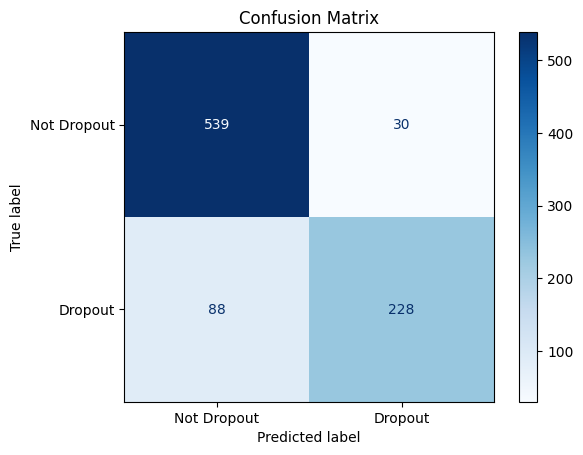

In [4]:
# Logistic regression on scaled features
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_binary, test_size=0.2, random_state=42)
logreg = LogisticRegression(max_iter=5000, solver='liblinear').fit(X_train, y_train)
evaluate(logreg, X_test, y_test)

Classification Report after SMOTE:
              precision    recall  f1-score   support

           0       0.87      0.87      0.87       569
           1       0.77      0.77      0.77       316

    accuracy                           0.83       885
   macro avg       0.82      0.82      0.82       885
weighted avg       0.83      0.83      0.83       885


Confusion Matrix after SMOTE:
[[495  74]
 [ 74 242]]


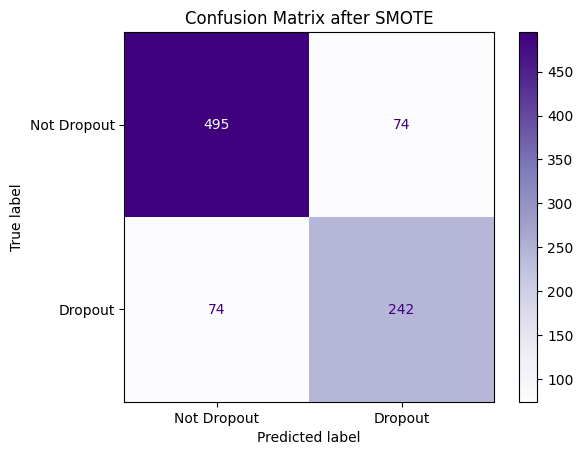

In [6]:
# Logistic regression with SMOTE to handle class imbalance
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y_binary, test_size=0.2, random_state=42)
X_train_smote, y_train_smote = SMOTE(random_state=42).fit_resample(X_train, y_train)
logreg = LogisticRegression(max_iter=1000).fit(X_train_smote, y_train_smote)
evaluate(logreg, X_test, y_test, suffix=" after SMOTE", cmap="Purples")

## Family Background Analysis

In [7]:
# Count a column's values among the 5 nearest neighbors of every student in a group
def get_neighbor_values(group_label, column):
    indices = df.index[df['Target'] == group_label]
    _, neighbor_idxs = knn.kneighbors(X_scaled[indices])
    return pd.Series(column.to_numpy()[neighbor_idxs[:, 1:].ravel()]).value_counts()

# Print the top 5 values of a parent feature for each (label, target) group
def print_top_by_group(feature, groups):
    for label, target in groups:
        for parent in ["Mother's", "Father's"]:
            print(f"\n{parent} {feature} for {label} student:")
            print(df[df['Target'] == target][f"{parent} {feature.lower()}"].value_counts().head(5))

In [8]:
# Most common mother's occupations among KNN neighbors of graduated and dropout students
for label, target in [("graduated", "Graduate"), ("dropout", "Dropout")]:
    print(f"Most common mother's occupations among neighbors of {label} students:\n")
    print(get_neighbor_values(target, X["Mother's occupation"]).head(5))

Most common mother's occupations among neighbors of graduated students:

9    4206
4    1995
5    1404
3     900
7     817
Name: count, dtype: int64
Most common mother's occupations among neighbors of dropout students:

9    2625
4    1210
5     813
3     563
2     501
Name: count, dtype: int64


In [9]:
# Most common parent occupations by student outcome
print_top_by_group("Occupation", [("dropout", "Dropout"), ("Graduated", "Graduate"), ("Enrolled", "Enrolled")])

#9 - Unskilled Workers
#4 - Administrative staff
#5 - Personal Services, Security and Safety Workers and Sellers
#7 - Skilled Workers in Industry, Construction and Craftsmen
#3 - Intermediate Level Technicians and Professions
#2 - Specialists in Intellectual and Scientific Activities
#0 - Student


Mother's Occupation for dropout student:
Mother's occupation
9    490
4    248
5    156
2    102
0     99
Name: count, dtype: int64

Father's Occupation for dropout student:
Father's occupation
9    323
7    184
5    148
4    139
3    114
Name: count, dtype: int64

Mother's Occupation for Graduated student:
Mother's occupation
9    823
4    422
5    280
3    177
7    144
Name: count, dtype: int64

Father's Occupation for Graduated student:
Father's occupation
9    524
7    371
5    261
3    207
4    173
Name: count, dtype: int64

Mother's Occupation for Enrolled student:
Mother's occupation
9    264
4    147
5     94
3     79
2     78
Name: count, dtype: int64

Father's Occupation for Enrolled student:
Father's occupation
9    163
7    111
5    107
4     74
3     63
Name: count, dtype: int64


In [10]:
# Most common parent qualifications by student outcome
# Note: the "dropout" rows filter Enrolled students, as in the original notebook
print_top_by_group("qualification", [("dropout", "Enrolled"), ("graduate", "Graduate"), ("enrolled", "Enrolled")])

#37 - Basic education 1st cycle (4th/5th year) or equiv
#1 - Secondary Education - 12th Year of Schooling or Eq.
#19 - Basic Education 3rd Cycle (9th/10th/11th Year) or Equiv.
#38 - Basic Education 2nd Cycle (6th/7th/8th Year) or Equiv.
#3 - Basic Education 1st Cycle (4th/5th Year) or Equiv.


Mother's qualification for dropout student:
Mother's qualification
1     204
19    176
37    169
3     101
38     91
Name: count, dtype: int64

Father's qualification for dropout student:
Father's qualification
37    199
19    183
1     172
38    127
3      62
Name: count, dtype: int64

Mother's qualification for graduate student:
Mother's qualification
1     565
19    506
37    457
38    331
3     198
Name: count, dtype: int64

Father's qualification for graduate student:
Father's qualification
37    578
19    521
1     451
38    408
3     130
Name: count, dtype: int64

Mother's qualification for enrolled student:
Mother's qualification
1     204
19    176
37    169
3     101
38     91
Name: count, dtype: int64

Father's qualification for enrolled student:
Father's qualification
37    199
19    183
1     172
38    127
3      62
Name: count, dtype: int64


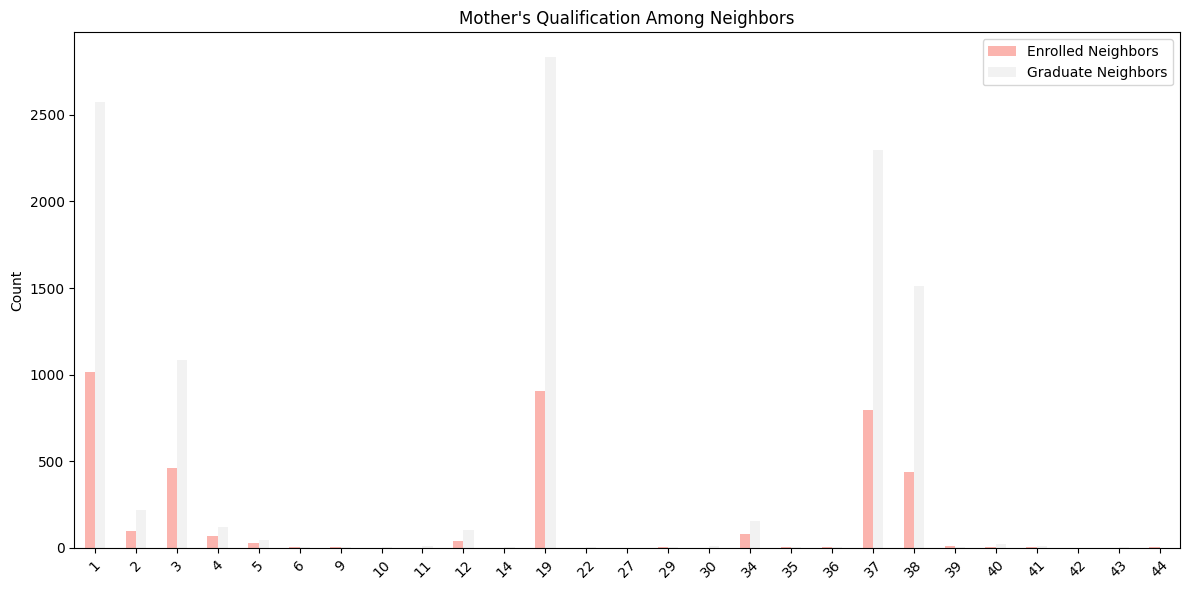

In [11]:
# Mother's qualification among KNN neighbors of enrolled and graduate students
comparison_df = pd.DataFrame({
    'Enrolled Neighbors': get_neighbor_values('Enrolled', X["Mother's qualification"]),
    'Graduate Neighbors': get_neighbor_values('Graduate', X["Mother's qualification"])
}).fillna(0)

comparison_df.plot(kind='bar', figsize=(12, 6), colormap='Pastel1')
plt.title("Mother's Qualification Among Neighbors")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Feature Influence and Model Evaluation

In [12]:
# Most influential features by logistic regression coefficient
# (Admission grade and both semester grades are already part of X_encoded)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_binary, test_size=0.2, random_state=42)
logreg = LogisticRegression(max_iter=1000).fit(X_train, y_train)

print("Classification Report:")
print(classification_report(y_test, logreg.predict(X_test)))

coef_df = pd.DataFrame({'Feature': X_encoded.columns, 'Coefficient': logreg.coef_[0]}
                       ).sort_values(by='Coefficient', key=abs, ascending=False)
print("\n Top Influential Features (Logistic Regression Coefficients):")
print(coef_df.head(10))

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.95      0.90       569
           1       0.88      0.72      0.79       316

    accuracy                           0.87       885
   macro avg       0.87      0.83      0.85       885
weighted avg       0.87      0.87      0.86       885


 Top Influential Features (Logistic Regression Coefficients):
                                Feature  Coefficient
30  Curricular units 2nd sem (approved)    -1.866441
28  Curricular units 2nd sem (enrolled)     1.114171
24  Curricular units 1st sem (approved)    -0.976295
16              Tuition fees up to date    -0.762553
27  Curricular units 2nd sem (credited)     0.484580
21  Curricular units 1st sem (credited)     0.420171
19                    Age at enrollment     0.382771
31     Curricular units 2nd sem (grade)    -0.368263
10                  Mother's occupation    -0.336134
25     Curricular units 1st sem (grade)     0.291597


In [13]:
# ROC-AUC for a default logistic regression model
model = LogisticRegression().fit(X_train, y_train)
roc_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

print("ROC-AUC Score:", roc_auc)
print("ROC-AUC Score of 0.92 means it has excellent predictive power, close to 1.0")

ROC-AUC Score: 0.9125102889813352
ROC-AUC Score of 0.92 means it has excellent predictive power, close to 1.0


In [14]:
# Matthews Correlation Coefficient for the same model
mcc = matthews_corrcoef(y_test, model.predict(X_test))
print("Matthews Correlation Coefficient:", mcc)

#MCC close to 1.0 indicates a strong correlation between predicted and actual classes.
#0.705 is a good MCC score, indicating a strong correlation between predicted and actual classes

Matthews Correlation Coefficient: 0.7050972328190312


In [15]:
# Top 10 influential features by Random Forest
rf = RandomForestClassifier(random_state=42).fit(X_train, y_train)
rf_importance = pd.Series(rf.feature_importances_, index=X_encoded.columns).sort_values(ascending=False)

print("\nTop Influential Features (Random Forest):")
print(rf_importance.head(10))


Top Influential Features (Random Forest):
Curricular units 2nd sem (approved)       0.153905
Curricular units 2nd sem (grade)          0.141506
Curricular units 1st sem (approved)       0.080268
Curricular units 1st sem (grade)          0.063830
Tuition fees up to date                   0.063040
Age at enrollment                         0.040424
Curricular units 2nd sem (evaluations)    0.038035
Admission grade                           0.035900
Previous qualification (grade)            0.033026
Course                                    0.032665
dtype: float64
